In [ ]:
!pip install yfinance vaderSentiment pandas matplotlib feedparser requests
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
import feedparser as fp


In [ ]:
company = "AAPL"
start_date = input("what start date? enter as yyyy-mm-dd")
end_date = input("what end date? enter as yyyy-mm-dd")
stock_data = yf.download(company, start = start_date, end =end_date)
stock_data["Returns"] = stock_data["Close"].pct_change()
stock_clean = stock_data.reset_index()
stock_clean.columns = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Returns']


stock_clean['Date'] = pd.to_datetime(stock_clean['Date']).dt.date



what start date? enter as yyyy-mm-dd2021-02-11
what end date? enter as yyyy-mm-dd2021-08-18


/tmp/ipykernel_1187/3011382700.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(company, start = start_date, end =end_date)
[*********************100%***********************]  1 of 1 completed


In [ ]:
#URL = "https://cdn.feedcontrol.net/16674/32638-czTFAmc4vSV7h.xml"
#feed = fp.parse(URL)
#x = []
#for entry in feed.entries:
  #x.append(entry.title)
#print(x)



In [ ]:
import kagglehub
import os
import pandas as pd

# Download and load the dataset fresh
path = kagglehub.dataset_download("abhishek1812j/apple-stock-news-dataset-20202022")
file_path = os.path.join(path, "apple_news_2020_2022.csv")
dataset = pd.read_csv(file_path)
filtered_dataset = dataset[(dataset['date'] >= start_date) & (dataset['date'] <= end_date)]
filtered_dataset = filtered_dataset.sort_values(by = 'date')

Using Colab cache for faster access to the 'apple-stock-news-dataset-20202022' dataset.


In [ ]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

x = []
for data in filtered_dataset["title"]:
    score_dict = analyzer.polarity_scores(data)
    compound_score = score_dict['compound']
    x.append(compound_score)

filtered_dataset['Sentiment'] = x


In [ ]:
daily_sentiment = filtered_dataset.groupby('date')['Sentiment'].mean().reset_index()
print(daily_sentiment.head(5))

         date  Sentiment
0  2021-02-16     0.0000
1  2021-02-18     0.0000
2  2021-02-19     0.0000
3  2021-02-20     0.5106
4  2021-02-22    -0.4939


In [ ]:
stock_clean['Date'] = pd.to_datetime(stock_clean['Date'])
filtered_dataset['date'] = pd.to_datetime(filtered_dataset['date'])
merged_df = pd.merge(stock_clean, filtered_dataset, left_on= 'Date', right_on= 'date', how = 'inner')
print(merged_df['Sentiment'].head(7))

0    0.0000
1    0.0000
2    0.0000
3    0.0000
4    0.0000
5   -0.4939
6    0.6808
Name: Sentiment, dtype: float64


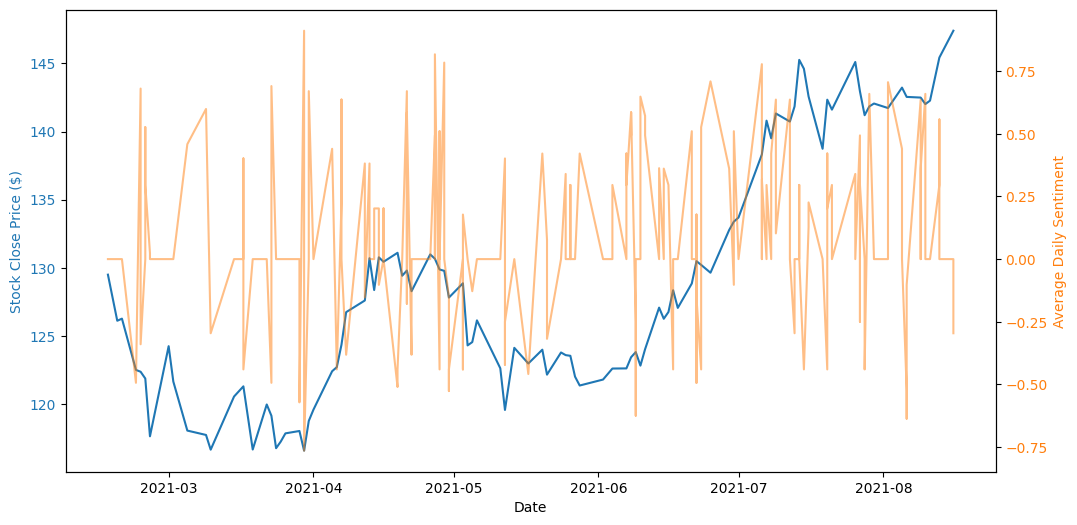

In [ ]:
import matplotlib
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('Stock Close Price ($)', color=color)
ax1.plot(merged_df['date'], merged_df['Close'], color=color, label='Stock Price')
ax1.tick_params(axis='y', labelcolor=color)

# Create a second y-axis that shares the same x-axis
ax2 = ax1.twinx()

# Plot Sentiment Score on the right axis (ax2)
color = 'tab:orange'
ax2.set_ylabel('Average Daily Sentiment', color=color)
ax2.plot(merged_df['date'], merged_df['Sentiment'], color=color, alpha=0.5, label='Sentiment')
ax2.tick_params(axis='y', labelcolor=color)